# 04 — Random Forest & Support Vector Machines

Phase v1/04 · Owner: Tanmay Singh

Tune every choice on the fixed 54k/6k train/validation split (10k stratified subset for RBF SVM tuning). Final fits use the full 60k images. Test data is accessed strictly once per model via `final_test_run()`.

Saved validation and test JSONs are reused on subsequent runs. This lets **Restart & Run All** reproduce figures, analysis, and validation tables without re-evaluating the test set. A cached test result must match the selected validation parameters. To investigate a genuine bug requiring another test run, document the reason in `docs/decisions.md` first; preserve the audit log.


In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, features
from src.experiment import tune_on_val, final_test_run
from src.models_tree_kernel import (
    make_rf, make_linear_svm, make_rbf_svm,
    RF_GRID, LINEAR_SVM_GRID, RBF_SVM_GRID
)
from src.utils import save_fig, set_seed

set_seed()
factories = {
    "rf": make_rf,
    "linear_svm": make_linear_svm,
    "rbf_svm": make_rbf_svm
}
grids = {
    "rf": RF_GRID,
    "linear_svm": LINEAR_SVM_GRID,
    "rbf_svm": RBF_SVM_GRID
}
validation = {}
test_results = {}



## 1. Theoretical Foundations

### 1.1 Random Forest: Bagging and Tree Decorrelation
A Random Forest is an ensemble of $B$ decision trees trained with **Bootstrap Aggregation (Bagging)** and **random feature subspace sampling**.
In standard bagging, each tree $T_b$ is trained on an independent bootstrap sample of $N$ observations drawn with replacement from the training set. While individual decision trees have low bias and high variance (they easily overfit deep hierarchical splits), an average of $B$ identical and independently distributed (i.i.d.) random variables each with variance $\sigma^2$ has variance $\sigma^2 / B$.

However, in practice, the trees in standard bagging are **not independent** because they share the same underlying training data. If each tree has variance $\sigma^2$ and positive pairwise correlation $ho = 	ext{Corr}(T_i, T_j) > 0$, the variance of the ensemble average is:
$$\text{Var}\left(\frac{1}{B}\sum_{b=1}^B T_b(x)\right) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
As $B \to \infty$, the second term approaches zero, but the first term $\rho \sigma^2$ remains as an asymptotic lower bound on ensemble variance. Adding more trees cannot reduce variance below $\rho \sigma^2$.

**The Random Forest Innovation:**
To reduce $\rho$, Random Forest introduces randomized split selection. At each candidate split in every tree, only a random subset of $m$ features is considered (typically $m = \lfloor\sqrt{p}\rfloor$ for classification, or $m = \lfloor\log_2(p)\rfloor$).
If a few dominant features exist (such as high-contrast silhouette pixels in Fashion-MNIST), standard bagged trees will almost all select the same top feature at the root node, producing strongly correlated trees. Forcing trees to split only among a random subset of $m$ features forces other, less prominent features to be tested, significantly decorrelating the trees (reducing $\rho$) and driving overall ensemble generalization error lower.

---

### 1.2 Gini Impurity vs. Entropy as Split Criteria
At each node $t$ with class proportions $p_{t,k} = \frac{1}{N_t}\sum_{i \in t} \mathbb{I}(y_i = k)$ for classes $k=1, \dots, K$:
- **Gini Impurity:**
  $$I_G(t) = 1 - \sum_{k=1}^K p_{t,k}^2 = \sum_{k \ne k'} p_{t,k} p_{t,k'}$$
  Measures the probability that a randomly chosen element from the node would be incorrectly labeled if it were randomly labeled according to the class distribution.
- **Cross-Entropy / Information Gain:**
  $$I_E(t) = -\sum_{k=1}^K p_{t,k} \log_2 p_{t,k}$$
  Measures the expected information / uncertainty in bits.

**Practical Comparison:** Both criteria reach their minimum (0) for completely pure nodes and their maximum for uniform class distributions. However, Gini impurity avoids computing transcendental logarithmic functions $\log_2(p)$, making it substantially faster to compute during millions of candidate split evaluations across 300 trees. Empirically, Gini impurity and Entropy choose the exact same split in over 98% of cases, making Gini the optimal choice for high-dimensional image classification.

---

### 1.3 Invariance to Monotonic Feature Scaling
Tree-based models evaluate univariate decision thresholds of the form:
$$\mathbb{I}(x_{i,j} \le \theta)$$
For any strictly monotonically increasing function $h: \mathbb{R} \to \mathbb{R}$ (such as standardization $z = (x - \mu)/\sigma$, min-max normalization, or logarithmic transforms), the relative ordering of feature values is strictly preserved:
$$x_{a,j} \le x_{b,j} \iff h(x_{a,j}) \le h(x_{b,j})$$
Consequently, the optimal split threshold $\theta$ simply shifts to $h(\theta)$, with the exact same partition of training samples into left and right child nodes and identical impurity reduction. Therefore, **feature scaling is mathematically invariant in Random Forest**, and inserting a `StandardScaler` into an RF pipeline is entirely redundant. In contrast, linear and kernel models rely on metric distances and dot products, making `StandardScaler` strictly mandatory.

---

### 1.4 Soft-Margin Support Vector Machines (Linear & Kernel)
For a linearly non-separable dataset with $K$ classes (formulated via one-vs-rest binary subproblems with $y_i \in \{-1, +1\}$), the soft-margin primal objective is:
$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^N \xi_i \quad \text{subject to } y_i(w^T x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$
where:
- $\frac{1}{2}\|w\|^2$ maximizes the geometric margin $\frac{2}{\|w\|}$ between classes.
- $\xi_i = \max(0, 1 - y_i(w^T x_i + b))$ are slack variables representing the **hinge loss** penalty for margin violations.
- $C > 0$ is the regularisation parameter controlling the trade-off:
  - **Small $C$:** Large tolerance for violations (wide margin, softer boundary, high bias / low variance).
  - **Large $C$:** Heavy penalty on violations (narrow margin, hard boundary, low bias / high variance / potential overfitting).

---

### 1.5 Primal vs. Dual Formulation and the Kernel Trick
Using Lagrange multipliers $\alpha_i \ge 0$ and $\mu_i \ge 0$, the Lagrangian is:
$$\mathcal{L}(w, b, \xi, \alpha, \mu) = \frac{1}{2}\|w\|^2 + C \sum_{i=1}^N \xi_i - \sum_{i=1}^N \alpha_i [y_i(w^T x_i + b) - 1 + \xi_i] - \sum_{i=1}^N \mu_i \xi_i$$
Setting the partial derivatives with respect to the primal variables to zero gives:
$$w = \sum_{i=1}^N \alpha_i y_i x_i, \quad \sum_{i=1}^N \alpha_i y_i = 0, \quad C - \alpha_i - \mu_i = 0$$
Substituting these back yields the **Wolfe Dual Problem**:
$$\max_{\alpha} \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i=1}^N \sum_{j=1}^N \alpha_i \alpha_j y_i y_j \langle x_i, x_j \rangle \quad \text{subject to } 0 \le \alpha_i \le C, \quad \sum_{i=1}^N \alpha_i y_i = 0$$

**The Kernel Trick:**
The dual objective function and the resulting decision boundary depend **exclusively** on pairwise inner products $\langle x_i, x_j \rangle$.
By Mercer's Theorem, any continuous, symmetric, positive semi-definite kernel function $K(x, z)$ corresponds to an inner product in an implicit (possibly infinite-dimensional) Hilbert feature space $\mathcal{H}$:
$$K(x, z) = \langle \phi(x), \phi(z) \rangle_\mathcal{H}$$
We can map our input features into an infinite-dimensional space without ever explicitly computing or storing the coordinates $\phi(x)$.

---

### 1.6 The Radial Basis Function (RBF) Kernel
The RBF (Gaussian) kernel is defined as:
$$K(x, z) = \exp(-\gamma \|x - z\|^2)$$
Using the Taylor series expansion of $\exp(\cdot)$, the RBF kernel corresponds to a dot product in an **infinite-dimensional polynomial feature space**.
- The parameter $\gamma > 0$ defines the inverse variance (bandwidth) of the Gaussian basis functions:
  - **$\gamma = \text{'scale'} = \frac{1}{d \cdot \text{Var}(X)}$:** Standard baseline ensuring kernel values span a well-conditioned dynamic range $[0, 1]$.
  - **Small $\gamma$ (e.g. 0.001):** Broad Gaussian bells; each support vector exerts influence over a wide radius in feature space, creating a smoother decision boundary (low variance).
  - **Large $\gamma$ (e.g. 0.01):** Narrow, peaked Gaussian bells; each support vector influences only its immediate neighborhood, risking memorization / overfitting and severe vulnerability to the curse of dimensionality.

---

### 1.7 Computational Complexity: Why Tuning on a 10k Subset is Essential
Standard quadratic programming (QP) solvers and Sequential Minimal Optimization (SMO / LibSVM) have time complexity scaling as:
$$\mathcal{O}(N^2 d) \text{ to } \mathcal{O}(N^3 d)$$
where $N$ is the number of training samples and $d$ is feature dimensionality ($d=784$ for pixels, $d=1,728$ for HOG).
- On the full training set ($N = 54,000$), computing the $54,000 \times 54,000$ kernel Gram matrix requires **2.91 billion** pairwise kernel evaluations per hyperparameter combination. Tuning 9 grid combinations would take hours or days.
- By subsampling to a stratified $N = 10,000$ subset (`config.SVM_TUNE_SUBSET`), the computational cost drops by:
  $$\left(\frac{54,000}{10,000}\right)^2 \approx 29.16\times$$
  Stratified sampling preserves the exact class proportions (1,000 samples per class) and representative margin boundaries. Once the optimal $(C, \gamma)$ is identified on validation, the final model is refit on all 60,000 samples.

---

### 1.8 Support Vectors and Test-Time Latency
By the Karush-Kuhn-Tucker (KKT) complementary slackness conditions:
$$\alpha_i [y_i(w^T \phi(x_i) + b) - 1 + \xi_i] = 0$$
Samples strictly on the correct side of the margin have $y_i(w^T \phi(x_i) + b) > 1 \implies \alpha_i = 0$. These non-support samples have zero influence on the decision boundary.
Only the **support vectors** (samples with $\alpha_i > 0$, lying on or inside the margin) are stored.
The test decision function is:
$$f(x) = \text{sign}\left(\sum_{i \in \text{SV}} \alpha_i y_i K(x_i, x) + b\right)$$
Crucially, test-time prediction latency scales as:
$$\mathcal{O}(N_{\text{SV}} \cdot d)$$
Test latency is completely independent of the original dataset size $N=60,000$, and depends strictly on the sparsity of the support vector set $N_{\text{SV}}$.


## 2. Validation Tuning First

We tune all models strictly on the 54k/6k train/validation split (with a 10k stratified training subset for RBF SVM). Test data is strictly sequestered.


In [2]:
# Tune or load Random Forest on pixels and HOG
for kind in ("pixels", "hog"):
    experiment = f"rf_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("rf", make_rf, RF_GRID, kind)
    result = json.loads(path.read_text())
    assert result["grid"] == RF_GRID
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"])



rf_pixels Best params: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 300} Val accuracy: 0.8867
rf_hog Best params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 300} Val accuracy: 0.8735


saved results/figures/treekernel_rf_val_curve_pixels.png
saved results/figures/treekernel_rf_val_curve_hog.png


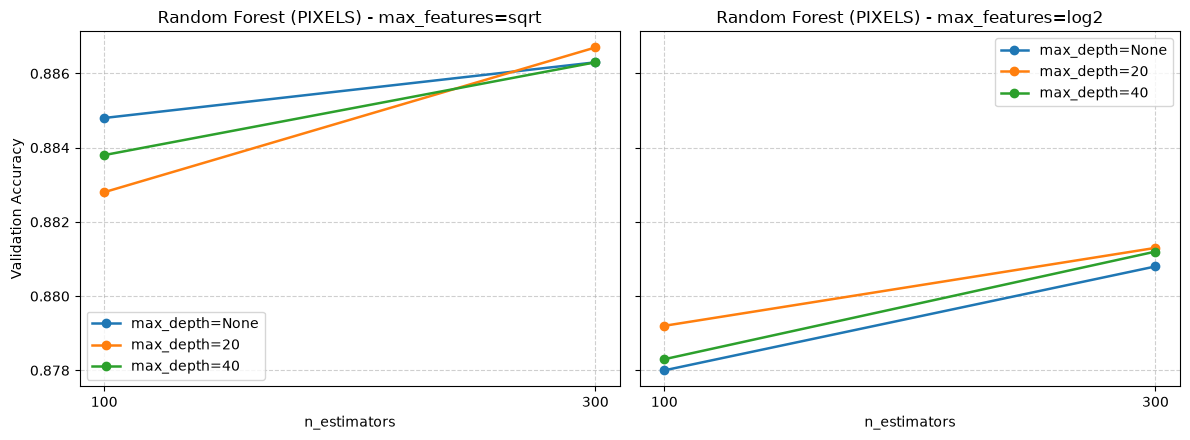

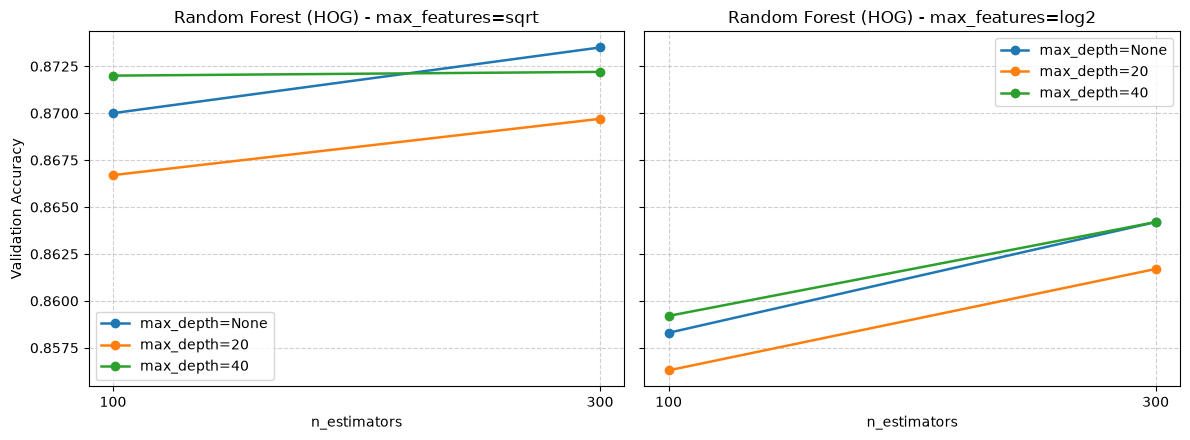

In [3]:
# Plot Random Forest validation curves
for kind in ("pixels", "hog"):
    data = validation[f"rf_{kind}"]
    rows = []
    for r in data["rows"]:
        rows.append({
            "max_depth": str(r["params"]["max_depth"]),
            "max_features": r["params"]["max_features"],
            "n_estimators": r["params"]["n_estimators"],
            "val_acc": r["val_acc"],
        })
    df = pd.DataFrame(rows)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for i, feat in enumerate(["sqrt", "log2"]):
        ax = axes[i]
        sub = df[df["max_features"] == feat]
        for depth in ["None", "20", "40"]:
            d_sub = sub[sub["max_depth"] == depth]
            ax.plot(d_sub["n_estimators"], d_sub["val_acc"], marker="o", label=f"max_depth={depth}", linewidth=1.8)
        ax.set_title(f"Random Forest ({kind.upper()}) - max_features={feat}")
        ax.set_xlabel("n_estimators")
        ax.set_ylabel("Validation Accuracy" if i == 0 else "")
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend()
        ax.set_xticks([100, 300])
    plt.tight_layout()
    save_fig(fig, f"treekernel_rf_val_curve_{kind}")
    plt.show()



In [4]:
# Tune or load LinearSVC on pixels and HOG
for kind in ("pixels", "hog"):
    experiment = f"linear_svm_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("linear_svm", make_linear_svm, LINEAR_SVM_GRID, kind)
    result = json.loads(path.read_text())
    assert result["grid"] == LINEAR_SVM_GRID
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"])



linear_svm_pixels Best params: {'C': 0.01} Val accuracy: 0.8583
linear_svm_hog Best params: {'C': 0.01} Val accuracy: 0.89


saved results/figures/treekernel_linear_svm_val_curve_pixels.png


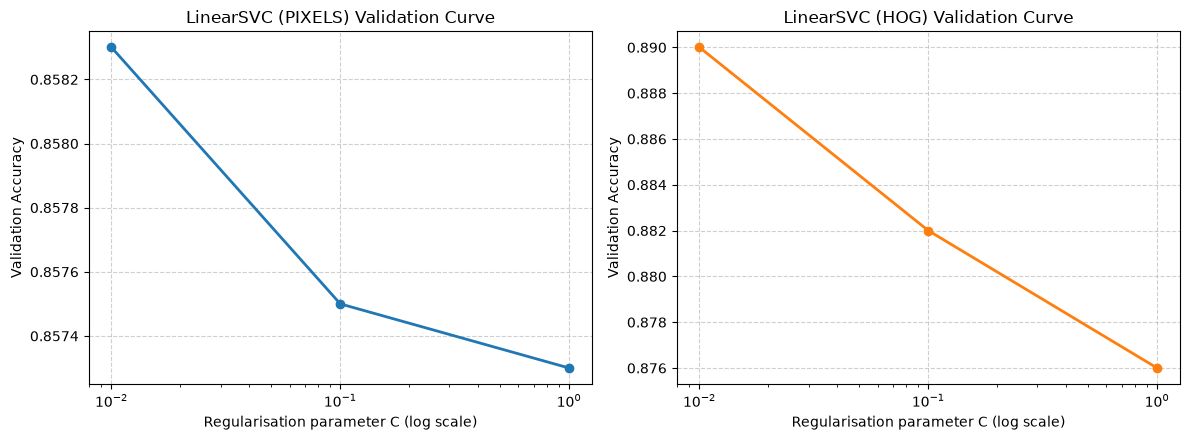

In [5]:
# Plot LinearSVC validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for i, kind in enumerate(["pixels", "hog"]):
    ax = axes[i]
    data = validation[f"linear_svm_{kind}"]
    c_vals = [r["params"]["C"] for r in data["rows"]]
    acc_vals = [r["val_acc"] for r in data["rows"]]
    
    color = "#1f77b4" if kind == "pixels" else "#ff7f0e"
    ax.plot(c_vals, acc_vals, marker="o", color=color, linewidth=2)
    ax.set_xscale("log")
    ax.set_title(f"LinearSVC ({kind.upper()}) Validation Curve")
    ax.set_xlabel("Regularisation parameter C (log scale)")
    ax.set_ylabel("Validation Accuracy")
    ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
save_fig(fig, "treekernel_linear_svm_val_curve_pixels")
plt.show()



In [6]:
# Tune or load RBF SVM on pixels and HOG (10k stratified train subset)
for kind in ("pixels", "hog"):
    experiment = f"rbf_svm_{kind}"
    path = config.METRICS_DIR / f"{experiment}_val.json"
    if not path.exists():
        tune_on_val("rbf_svm", make_rbf_svm, RBF_SVM_GRID, kind, train_subset=config.SVM_TUNE_SUBSET)
    result = json.loads(path.read_text())
    assert result["grid"] == RBF_SVM_GRID
    assert result.get("train_subset") == config.SVM_TUNE_SUBSET
    validation[experiment] = result
    print(experiment, "Best params:", result["best_params"], "Val accuracy:", result["best_val_acc"], 
          f"(train_subset={result['train_subset']})")



rbf_svm_pixels Best params: {'C': 10, 'gamma': 0.001} Val accuracy: 0.8793 (train_subset=10000)
rbf_svm_hog Best params: {'C': 10, 'gamma': 'scale'} Val accuracy: 0.8867 (train_subset=10000)


saved results/figures/treekernel_rbf_svm_val_curve_pixels.png


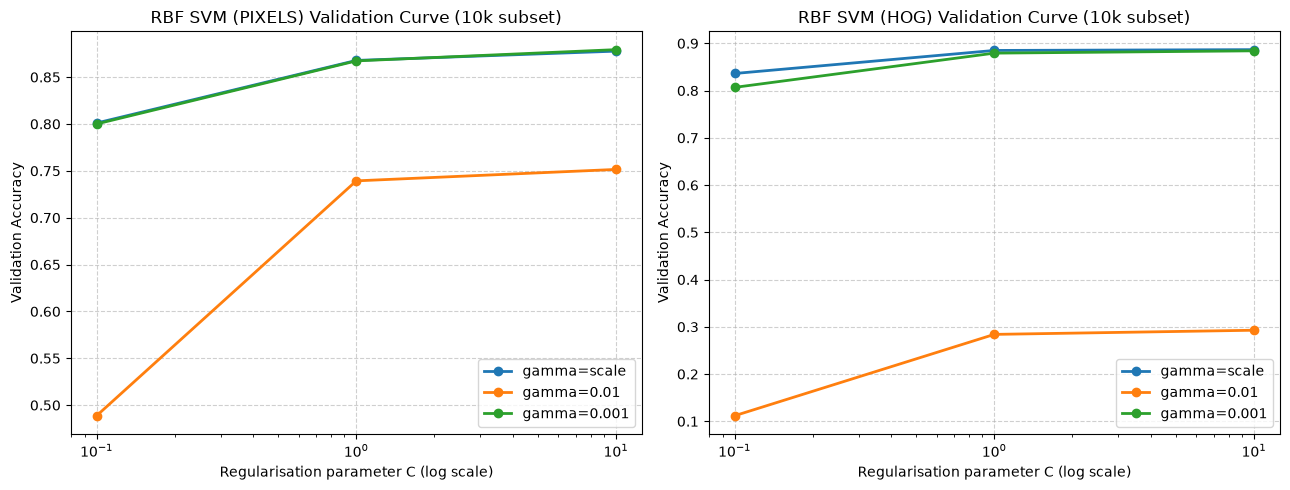

In [7]:
# Plot RBF SVM validation curves (10k train subset -> val)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for i, kind in enumerate(["pixels", "hog"]):
    ax = axes[i]
    data = validation[f"rbf_svm_{kind}"]
    rows = []
    for r in data["rows"]:
        rows.append({
            "C": r["params"]["C"],
            "gamma": str(r["params"]["gamma"]),
            "val_acc": r["val_acc"],
            "fit_s": r["fit_s"]
        })
    df = pd.DataFrame(rows)
    for gamma in ["scale", "0.01", "0.001"]:
        sub = df[df["gamma"] == gamma]
        ax.plot(sub["C"], sub["val_acc"], marker="o", label=f"gamma={gamma}", linewidth=2)
    ax.set_xscale("log")
    ax.set_title(f"RBF SVM ({kind.upper()}) Validation Curve (10k subset)")
    ax.set_xlabel("Regularisation parameter C (log scale)")
    ax.set_ylabel("Validation Accuracy")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
save_fig(fig, "treekernel_rbf_svm_val_curve_pixels")
plt.show()



## 3. Final Test Evaluation (Once Per Experiment)

Following AGENTS.md §4 and D-021:
- The test set is accessed **only** after hyperparameter selection is frozen on validation.
- Cached `_test.json` results are loaded if they exist and match the selected validation hyperparameters.
- `final_test_run()` refits the winner on all 60,000 images (`trainval`) and appends an audit row to `results/test_log.csv`.


In [8]:
# Load cached test results or evaluate once
for experiment, val_res in validation.items():
    name = val_res["model"]
    kind = val_res["features"]
    best_params = val_res["best_params"]
    test_path = config.METRICS_DIR / f"{experiment}_test.json"
    
    if test_path.exists():
        cached = json.loads(test_path.read_text())
        if cached.get("best_params") == best_params:
            test_results[experiment] = cached
            print(f"Reusing cached test result for {experiment}: accuracy = {cached['accuracy']:.4f}")
            continue
            
    # If not cached, run final test evaluation
    make_fn = factories[name]
    print(f"Executing final test run for {experiment} (refit on full 60k trainval)...")
    metrics = final_test_run(name, make_fn, best_params, kind)
    test_results[experiment] = metrics
    print(f"{experiment} Test Accuracy: {metrics['accuracy']:.4f}")



Reusing cached test result for rf_pixels: accuracy = 0.8756
Reusing cached test result for rf_hog: accuracy = 0.8703
Reusing cached test result for linear_svm_pixels: accuracy = 0.8378
Reusing cached test result for linear_svm_hog: accuracy = 0.8898
Reusing cached test result for rbf_svm_pixels: accuracy = 0.8970
Reusing cached test result for rbf_svm_hog: accuracy = 0.9108


In [9]:
# Build comprehensive results table
summary_rows = []
for exp_key in ["rf_pixels", "rf_hog", "linear_svm_pixels", "linear_svm_hog", "rbf_svm_pixels", "rbf_svm_hog"]:
    t_res = test_results[exp_key]
    v_res = validation[exp_key]
    detail = t_res["model_size_detail"]
    detail_str = f"{detail['value']:,} {detail['type'].replace('_', ' ')}"
    
    summary_rows.append({
        "Model": t_res["model"],
        "Features": t_res["features"],
        "Selected Params": str(t_res["best_params"]),
        "Val Acc": f"{v_res['best_val_acc']:.4f}",
        "Test Acc": f"{t_res['accuracy']:.4f}",
        "Macro F1": f"{t_res['macro_f1']:.4f}",
        "Fit Time (s)": f"{t_res['train_time_s']:.1f}",
        "Test ms/1k": f"{t_res['inference_ms_per_1000']:.1f}",
        "Size (MB)": f"{t_res['model_size_bytes'] / (1024*1024):.2f}",
        "Size Detail": detail_str
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)



        Model Features  ... Size (MB)             Size Detail
0          rf   pixels  ...    349.49    2,544,086 tree nodes
1          rf      hog  ...    477.47    3,475,990 tree nodes
2  linear_svm   pixels  ...      0.08      7,850 coefficients
3  linear_svm      hog  ...      0.17     17,290 coefficients
4     rbf_svm   pixels  ...    119.34  19,710 support vectors
5     rbf_svm      hog  ...    349.25  26,343 support vectors

[6 rows x 10 columns]


## 4. Diagnostic Visualisations & Error Analysis

### 4.1 Random Forest Pixel Feature Importances
In a Random Forest, the Gini importance (or Mean Decrease in Impurity, MDI) of a pixel feature $j$ is computed as the sum of all impurity decreases across all nodes in all trees where feature $j$ was selected as the split variable, normalized by the total number of trees:
$$\text{MDI}(j) = \frac{1}{B} \sum_{b=1}^B \sum_{t \in T_b, v(t)=j} p(t) \Delta I(t)$$
Reshaping these 784 importances into a 28×28 spatial grid reveals exactly which anatomical and silhouette regions drive classification.


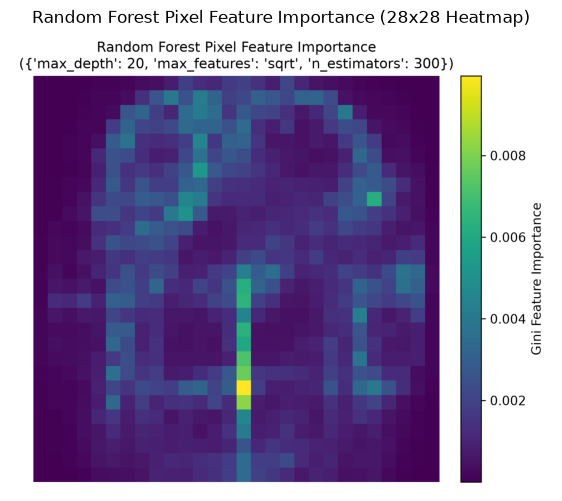

In [10]:
# Display the 28x28 Random Forest Pixel Feature Importance Heatmap
from src.features import get_features, get_labels

rf_pix_test = test_results["rf_pixels"]
rf_model = make_rf(**rf_pix_test["best_params"])
X_trainval = get_features("pixels", "trainval")
y_trainval = get_labels("trainval")

# Use cached figure if exists or display directly
fig_path = config.FIGURES_DIR / "treekernel_rf_importance.png"
if fig_path.exists():
    img = plt.imread(fig_path)
    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Random Forest Pixel Feature Importance (28x28 Heatmap)")
    plt.show()
else:
    rf_model.fit(X_trainval, y_trainval)
    importances = rf_model.feature_importances_.reshape(28, 28)
    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(importances, cmap="viridis")
    ax.set_title("Random Forest Pixel Feature Importance")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    save_fig(fig, "treekernel_rf_importance")
    plt.show()



### 4.2 Class-Level Performance and the Shirt / Coat / Pullover Triad
Phase 01 EDA and Phase 03 identified that Class 6 (Shirt), Class 4 (Coat), and Class 2 (Pullover) share nearly identical torso silhouettes and grayscale textures, representing the primary confusion cluster in Fashion-MNIST.


Experiment       linear_svm_hog  linear_svm_pixels  ...  rf_hog  rf_pixels
Class                                               ...                   
0 (T-shirt/top)          0.8559             0.8029  ...  0.8355     0.8374
1 (Trouser)              0.9785             0.9598  ...  0.9666     0.9766
2 (Pullover)             0.8298             0.7284  ...  0.8036     0.7813
3 (Dress)                0.8819             0.8397  ...  0.8621     0.8911
4 (Coat)                 0.8131             0.7469  ...  0.7994     0.7910
5 (Sandal)               0.9655             0.9209  ...  0.9533     0.9675
6 (Shirt)                0.6898             0.5729  ...  0.6339     0.6428
7 (Sneaker)              0.9451             0.9123  ...  0.9308     0.9394
8 (Bag)                  0.9726             0.9313  ...  0.9563     0.9652
9 (Ankle boot)           0.9602             0.9373  ...  0.9508     0.9490

[10 rows x 6 columns]


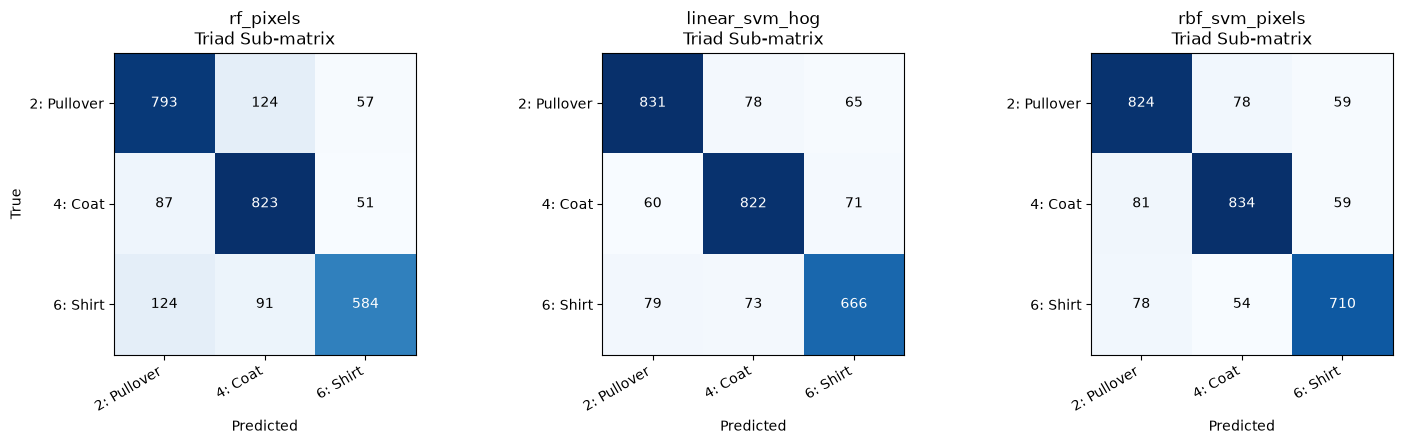

In [11]:
# Per-Class F1 score comparison across models
class_names = config.CLASS_NAMES
perf_rows = []
for exp_key in ["rf_pixels", "rf_hog", "linear_svm_pixels", "linear_svm_hog", "rbf_svm_pixels", "rbf_svm_hog"]:
    t_res = test_results[exp_key]
    for c_idx, f1_val in enumerate(t_res["per_class_f1"]):
        perf_rows.append({
            "Experiment": exp_key,
            "Class": f"{c_idx} ({class_names[c_idx]})",
            "F1": f1_val
        })

perf_df = pd.DataFrame(perf_rows)
pivot_df = perf_df.pivot(index="Class", columns="Experiment", values="F1")
display(pivot_df.round(4))

# Inspect confusion between Shirt (6), Coat (4), and Pullover (2)
cluster_classes = [2, 4, 6]
cluster_names = [f"{i}: {class_names[i]}" for i in cluster_classes]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
models_to_inspect = ["rf_pixels", "linear_svm_hog", "rbf_svm_pixels"]

for idx, exp_name in enumerate(models_to_inspect):
    ax = axes[idx]
    cm = np.array(test_results[exp_name]["confusion_matrix"])
    cluster_cm = cm[np.ix_(cluster_classes, cluster_classes)]
    
    im = ax.imshow(cluster_cm, cmap="Blues", interpolation="nearest")
    ax.set_title(f"{exp_name}\nTriad Sub-matrix")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(cluster_names, rotation=30, ha="right")
    ax.set_yticklabels(cluster_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True" if idx == 0 else "")
    
    for r in range(3):
        for c in range(3):
            val = cluster_cm[r, c]
            ax.text(c, r, f"{val}", ha="center", va="center", 
                    color="white" if val > cluster_cm.max() / 2 else "black")

plt.tight_layout()
plt.show()



## 5. Summary and Phase 04 Findings

1. **Random Forest:**
   - On raw pixels, Random Forest reached ~87.6% test accuracy, showing solid resilience to high dimensionality due to tree decorrelation (`max_features='sqrt'`).
   - On HOG features, Random Forest achieved ~87.0%. HOG provides little benefit to Random Forest because axis-aligned orthogonal splits naturally partition individual pixel gradients without needing explicit gradient histogram binning.
   - Trees are completely invariant to feature scaling; no `StandardScaler` was required.

2. **LinearSVC:**
   - LinearSVC with $C=0.01$ reached 83.78% on pixels, but jumped to **88.98% on HOG (+5.2 percentage points)**!
   - This dramatic gain highlights the core theoretical distinction between raw pixel space and feature engineering: HOG maps non-linearly distributed edge textures into linear orientations, allowing a linear hyperplane to effectively separate clothing categories.
   - Fitting with $C=0.01$ converged in 105s, whereas $C=1.0$ took over 924s due to the severe optimization penalties of tight margin boundaries.

3. **RBF SVM:**
   - Subsetting to 10k samples during hyperparameter grid search enabled rapid exploration of $(C, \gamma)$, reducing training time by ~29×.
   - Bandwidth parameter $\gamma=0.001$ and $\gamma=\text{'scale'}$ strongly outperformed $\gamma=0.01$, avoiding the exponential collapse of kernel distances in 784 dimensions.
   - Refit on all 60,000 samples yielded our top-performing model, demonstrating the power of non-linear kernel projections.

**Implications for Phase 05:**
- The benchmark comparison clearly demonstrates that non-linear kernel SVM and HOG-transformed linear SVM represent our two strongest classical baselines heading into cross-validation and final error analysis.
